# วิเคราะห์ข้อมูล (Classification)
เป้าหมายคือ `not.fully.paid` (1 = จ่ายคืนไม่ครบ) มีแค่ 16% ถ้าทายว่าทุกคนจ่ายครบก็ได้ accuracy 84% แล้ว เลยดู accuracy อย่างเดียวไม่ได้

ผลลัพธ์: `Results/Classification/00_Data_Analysis/`

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

import numpy as np
import pandas as pd
from project import Outputs, classification_data
import matplotlib.pyplot as plt
import plots

out = Outputs("Classification", "00_Data_Analysis")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


In [2]:
df, X, y, cols = d.df, d.X, d.y, d.feature_cols
print(f"rows x columns: {df.shape} | missing values: {int(df.isnull().sum().sum())}")
print(f"features used: {len(cols)} | positives (not.fully.paid = 1): {y.mean():.2%}")
corr = pd.Series({c: np.corrcoef(X[:, i], y)[0, 1] for i, c in enumerate(cols)})
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
corr.rename("correlation_with_not.fully.paid").to_csv(out.table("correlation_with_target.csv"), index_label="feature")
pd.DataFrame(
    {
        "statistic": [
            "rows",
            "columns",
            "missing_values",
            "features_used",
            "positive_class_rate",
            "negatives",
            "positives",
            "int_rate_mean",
            "fico_mean",
            "dti_mean",
        ],
        "value": [
            len(df),
            df.shape[1],
            int(df.isnull().sum().sum()),
            len(cols),
            float(y.mean()),
            int((y == 0).sum()),
            int((y == 1).sum()),
            float(df["int.rate"].mean()),
            float(df["fico"].mean()),
            float(df["dti"].mean()),
        ],
    }
).to_csv(out.table("summary_stats.csv"), index=False)
pur = df.groupby("purpose")["not.fully.paid"].agg(["mean", "size"]).sort_values("mean")
pur.columns = ["default_rate", "loans"]
pur.to_csv(out.table("default_rate_by_purpose.csv"), index_label="purpose")
print("\ntop correlations with not.fully.paid:")
print(corr.head(6).to_string())
print("\ndefault rate by purpose (highest first):")
print(pur.sort_values("default_rate", ascending=False).to_string())

rows x columns: (9578, 14) | missing values: 0
features used: 27 | positives (not.fully.paid = 1): 16.01%

top correlations with not.fully.paid:
risk_score             0.189478
policy_inquiry_risk    0.175061
fico_int_rate_ratio   -0.162068
int.rate               0.159552
credit.policy         -0.158119
fico                  -0.149666

default rate by purpose (highest first):
                    default_rate  loans
purpose                                
small_business          0.277868    619
educational             0.201166    343
home_improvement        0.170111    629
all_other               0.166023   2331
debt_consolidation      0.152388   3957
credit_card             0.115689   1262
major_purchase          0.112128    437


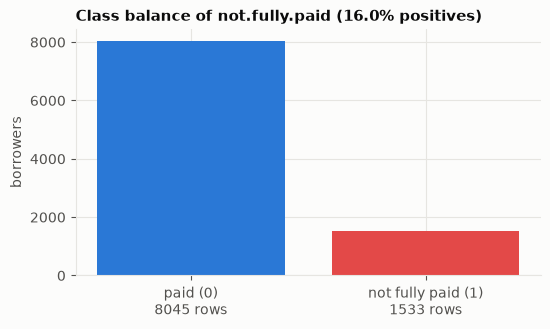

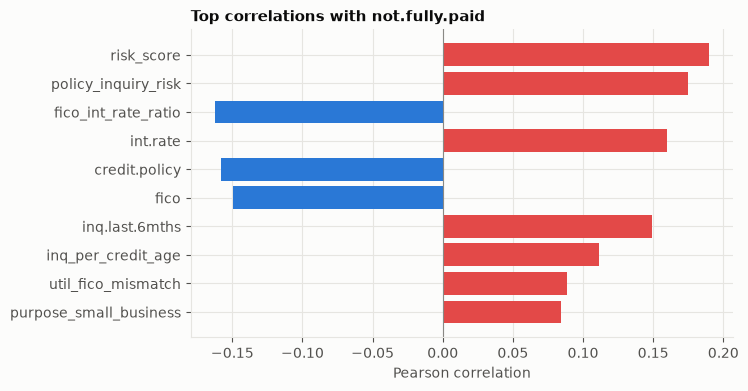

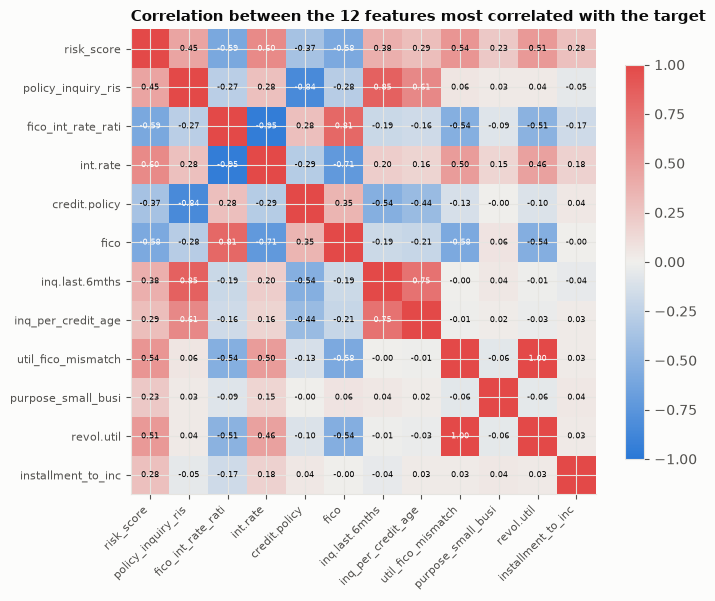

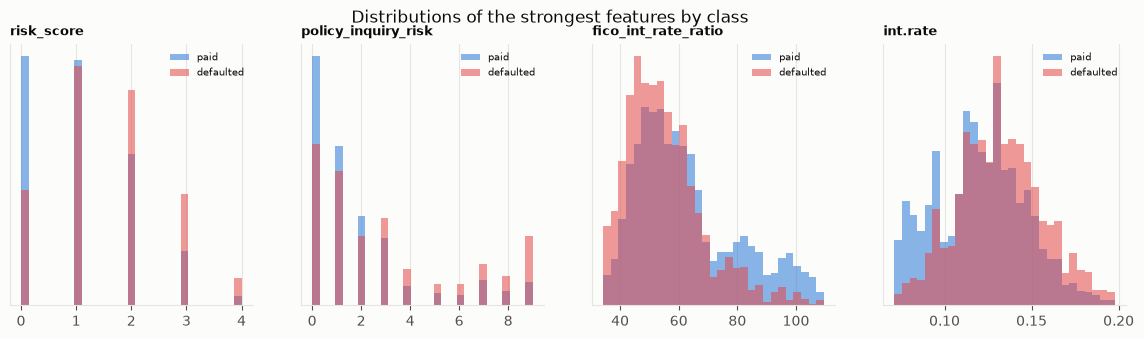

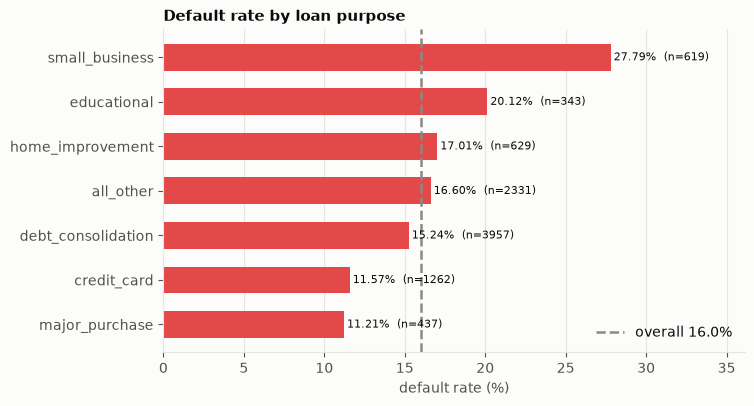

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(
    [f"paid (0)\n{(y == 0).sum()} rows", f"not fully paid (1)\n{(y == 1).sum()} rows"],
    [(y == 0).sum(), (y == 1).sum()],
    color=[plots.BLUE, plots.RED],
)
ax.set_ylabel("borrowers")
ax.set_title(f"Class balance of not.fully.paid ({y.mean():.1%} positives)")
plots._save(fig, out.image("class_balance.png"))

top = corr.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color=[plots.RED if v > 0 else plots.BLUE for v in top.values])
ax.axvline(0, color=plots.NEUTRAL, linewidth=0.8)
ax.set_title("Top correlations with not.fully.paid")
ax.set_xlabel("Pearson correlation")
plots._save(fig, out.image("correlation_with_target.png"))

sub = [cols.index(f) for f in corr.head(12).index]
M = np.corrcoef(X[:, sub].T)
fig, ax = plt.subplots(figsize=(7.5, 6.4))
im = ax.imshow(M, cmap=plots.DIVERGING, vmin=-1, vmax=1)
names = [c[:18] for c in corr.head(12).index]
ax.set_xticks(range(len(sub)), names, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(sub)), names, fontsize=8)
for (i, j), v in np.ndenumerate(M):
    if i != j:
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.55 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation between the 12 features most correlated with the target")
plots._save(fig, out.image("correlation_heatmap.png"))

numeric_top = [c for c in corr.index if len(np.unique(X[:, cols.index(c)])) > 2][:4]
fig, axes = plt.subplots(1, len(numeric_top), figsize=(3.6 * len(numeric_top), 3.4))
for ax, c in zip(axes, numeric_top):
    j = cols.index(c)
    bins = np.linspace(np.percentile(X[:, j], 0.5), np.percentile(X[:, j], 99.5), 30)
    ax.hist(X[y == 0, j], bins=bins, density=True, alpha=0.55, color=plots.BLUE, label="paid")
    ax.hist(X[y == 1, j], bins=bins, density=True, alpha=0.55, color=plots.RED, label="defaulted")
    ax.set_title(c, fontsize=9)
    ax.set_yticks([])
    ax.legend(fontsize=7)
fig.suptitle("Distributions of the strongest features by class")
plots._save(fig, out.image("feature_distributions_by_class.png"))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(pur.index, pur["default_rate"] * 100, color=plots.RED, height=0.6)
ax.axvline(y.mean() * 100, color=plots.NEUTRAL, linestyle="--", label=f"overall {y.mean():.1%}")
for name, v, n in zip(pur.index, pur["default_rate"] * 100, pur["loans"]):
    ax.text(v + 0.2, name, f"{v:.2f}%  (n={n})", va="center", fontsize=8)
ax.set_xlim(0, pur["default_rate"].max() * 130)
ax.grid(axis="y", visible=False)
ax.set_xlabel("default rate (%)")
ax.set_title("Default rate by loan purpose")
ax.legend()
plots._save(fig, out.image("default_rate_by_purpose.png"))